<a id="top" name="top" class="lab-anchor"></a>
<div class="lab-title">
<div class="kicker">Прикладная статистика · ИнфоХимия / КТвД</div>
<h1>Лабораторная работа 01</h1>
<p class="subtitle">Исследование трёх случайных величин<br>Первый спринт</p>
<div class="authors">Авторы и группы: <em>заполняются командой</em><br>Данные: <code>ASE10.csv</code> · Формат: Jupyter Notebook</div>
</div>


<a id="contents" name="contents" class="lab-anchor"></a>

## Оглавление

**[1. Исходные данные](#data)**  

**[2. Сигнал сенсора NO2](#rv-no2)**  
[Описание](#no2-description) · [EDA](#no2-eda) · [Распределение](#no2-model) · [Гипотеза](#no2-test) · [Нормализация](#no2-normalization) · [Оценки](#no2-estimates) · [Выборки](#no2-samples)

**[3. Сигнал сенсора температуры (ASE_T)](#rv-temp)**  
[Описание](#temp-description) · [EDA](#temp-eda) · [Распределение](#temp-model) · [Гипотеза](#temp-test) · [Нормализация](#temp-normalization) · [Оценки](#temp-estimates) · [Выборки](#temp-samples)

**[4. Зависимость NO2 от температуры](#dependence)**  
[Корреляция](#dependence-test) · [Графики](#dependence-plots) · [Вывод](#dependence-conclusion)

**[5. Сигнал сенсора CO](#rv-co)**  
[Описание](#co-description) · [EDA](#co-eda) · [Распределение](#co-model) · [Гипотеза](#co-test) · [Нормализация](#co-normalization) · [Оценки](#co-estimates) · [Выборки](#co-samples)

**[6. Lab resume](#resume)**  
[Таблица критериев](#criteria)

[Указатель рисунков и таблиц](#figure-index)

Код свёрнут; результаты расчётов оставлены видимыми. Навигационные ссылки размещены в начале и конце крупных разделов.

In [2]:
# Оформление отчёта. Расчётные ячейки ниже оставлены без изменений.
import functools as _design_functools
import textwrap as _design_textwrap
import matplotlib as _design_mpl
import matplotlib.pyplot as _design_plt
import seaborn as _design_sns
import pandas as _design_pd
from IPython.display import display as _design_display, HTML as _design_HTML
from matplotlib.collections import PathCollection as _DesignScatter, PolyCollection as _DesignFill

_DESIGN_CSS = '\n:root{--lab-ink:#243447;--lab-blue:#245B78;--lab-muted:#667789;--lab-line:#D9E2EA;--lab-paper:#fff;--lab-tint:#F4F7FA}\n.lab-title{border-top:4px solid #245B78;border-bottom:1px solid #D9E2EA;padding:28px 0 22px;margin:12px 0 20px;color:#243447}\n.lab-title .kicker{font-size:13px;letter-spacing:.08em;text-transform:uppercase;color:#667789}\n.lab-title h1{font-size:32px!important;line-height:1.2!important;font-weight:650!important;border:0!important;margin:15px 0 8px!important;color:#243447!important}\n.lab-title .subtitle{font-size:19px;line-height:1.45;margin:0 0 20px;color:#42576A}\n.lab-title .authors{font-size:14px;line-height:1.8;color:#556575}\n.lab-nav{border-top:1px solid #D9E2EA;border-bottom:1px solid #D9E2EA;padding:10px 0;margin:18px 0 24px;font-size:13px;display:flex;flex-wrap:wrap;gap:10px 24px}\n.lab-nav a,.lab-links a{color:#245B78;text-decoration:none!important}\n.lab-nav a:hover,.lab-links a:hover{text-decoration:underline!important}\n.lab-links{font-size:13px;line-height:1.8;color:#667789;margin:8px 0 16px}\n.lab-caption{font-size:13px;line-height:1.6;color:#5C6E7E;margin:10px 0 22px}\n.lab-anchor{scroll-margin-top:80px}\n.jp-RenderedHTMLCommon h1,.jp-RenderedHTMLCommon h2,.jp-RenderedHTMLCommon h3,.jp-RenderedHTMLCommon h4{color:#243447;line-height:1.4}\n.jp-RenderedHTMLCommon h2{border-top:1px solid #D9E2EA;padding-top:22px;margin-top:30px}\n.jp-RenderedHTMLCommon p,.jp-RenderedMarkdown p{line-height:1.75}\n.jp-RenderedHTMLCommon table:not(.dataframe){border-collapse:collapse;max-width:100%;width:100%;font-size:13px;margin:16px 0}\n.jp-RenderedHTMLCommon table th{background:#F0F5F8;color:#243447;text-align:left;border-bottom:2px solid #BCCBD7;padding:10px 12px}\n.jp-RenderedHTMLCommon table td{border-bottom:1px solid #E1E7ED;padding:9px 12px;vertical-align:top}\n.lab-table-wrap{overflow-x:auto;padding:6px 0 16px}\n.lab-table{border-collapse:collapse!important;width:100%!important;font-size:13px!important;color:#243447!important}\n.lab-table th{background:#F0F5F8!important;border:0!important;border-bottom:2px solid #BCCBD7!important;padding:10px 12px!important;text-align:right!important;white-space:normal!important}\n.lab-table td{border:0!important;border-bottom:1px solid #E1E7ED!important;padding:9px 12px!important;text-align:right!important;font-variant-numeric:tabular-nums!important}\n.lab-table tbody th{background:#fff!important;text-align:left!important;white-space:normal!important;border-bottom:1px solid #E1E7ED!important;font-weight:500!important}\n.lab-table tbody tr:nth-child(even) td,.lab-table tbody tr:nth-child(even) th{background:#F8FAFC!important}\n.lab-table thead th:first-child{text-align:left!important}\n.jp-RenderedImage img{max-width:100%;height:auto}\n.jp-OutputArea-output pre{font-size:13px;line-height:1.65}\n@media(max-width:640px){.lab-title h1{font-size:26px!important}.lab-title .subtitle{font-size:17px}.lab-nav{gap:7px 15px}}\n'
_design_display(_design_HTML("<style>" + _DESIGN_CSS + "</style>"))
_design_palette = ["#245B78", "#B87532", "#697A8C", "#477D73"]
_design_mpl.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10.5,
    "axes.titlesize": 13, "axes.titleweight": "semibold",
    "axes.labelsize": 10.5, "axes.labelcolor": "#243447",
    "text.color": "#243447", "xtick.color": "#5C6E7E", "ytick.color": "#5C6E7E",
    "axes.edgecolor": "#C7D3DD", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": _design_mpl.cycler(color=_design_palette),
    "grid.color": "#DEE6ED", "grid.linewidth": 0.6,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "savefig.facecolor": "white", "figure.dpi": 120, "savefig.dpi": 140,
    "legend.frameon": False, "legend.fontsize": 9.5,
    "axes.formatter.useoffset": False, "axes.formatter.limits": (-4, 7),
})
try:
    get_ipython().run_line_magic("config", "InlineBackend.figure_format = 'png'")
except (NameError, AttributeError):
    pass

# Явный цвет устраняет несовместимость histplot с некоторыми версиями Matplotlib.
# Данные, интервалы bins, KDE и параметры статистики не меняются.
_design_histplot_original = getattr(_design_sns.histplot, "_design_original", _design_sns.histplot)
@_design_functools.wraps(_design_histplot_original)
def _design_histplot(*args, **kwargs):
    if kwargs.get("hue") is None:
        kwargs.setdefault("color", _design_palette[0])
    return _design_histplot_original(*args, **kwargs)
_design_histplot._design_original = _design_histplot_original
_design_sns.histplot = _design_histplot

# Единый вид таблиц; исходные числовые значения DataFrame сохраняются.
_design_table_original = getattr(_design_pd.DataFrame._repr_html_, "_design_original", _design_pd.DataFrame._repr_html_)
def _design_table_repr(self):
    result = _design_table_original(self)
    if result is None:
        return None
    result = result.replace('class="dataframe"', 'class="dataframe lab-table"')
    return '<style>' + _DESIGN_CSS + '</style><div class="lab-table-wrap">' + result + '</div>'
_design_table_repr._design_original = _design_table_original
_design_pd.DataFrame._repr_html_ = _design_table_repr

# Меняются только визуальные свойства, а не данные или границы шкал.
_design_show_original = getattr(_design_plt.show, "_design_original", _design_plt.show)
_design_figure_number = 0

def _design_style_figure(figure):
    figure.set_size_inches(9.2, 4.8, forward=True)
    for axis in figure.axes:
        if axis.get_label() == "<colorbar>":
            axis.tick_params(labelsize=9)
            continue
        _is_heatmap = any(isinstance(v, _design_mpl.collections.QuadMesh) for v in axis.collections)
        _limits = (axis.get_xlim(), axis.get_ylim())
        _title = axis.get_title()
        axis.set_title("\n".join(_design_textwrap.wrap(_title, width=76)), loc="left", pad=18)
        axis.set_title("", loc="center")
        axis.set_axisbelow(True)
        if _is_heatmap:
            _heat_cmap = _design_mpl.colors.LinearSegmentedColormap.from_list(
                "lab-correlation", ["#245B78", "#F6F8FA", "#B87532"])
            for collection in axis.collections:
                if isinstance(collection, _design_mpl.collections.QuadMesh):
                    collection.set_cmap(_heat_cmap)
        if not _is_heatmap:
            axis.grid(False)
            axis.yaxis.grid(True, color="#DEE6ED", linewidth=0.6, alpha=0.9)
            for side in ["top", "right"]:
                axis.spines[side].set_visible(False)
            for side in ["bottom", "left"]:
                axis.spines[side].set_color("#C7D3DD")
            _line_index = 0
            for line in axis.lines:
                _label = line.get_label()
                _colour = _design_palette[_line_index % len(_design_palette)]
                if any(isinstance(c, _DesignScatter) for c in axis.collections):
                    _colour = _design_palette[1]
                if _label == "Среднее":
                    _colour = _design_palette[1]
                if _label == "Среднее выборки":
                    _colour = _design_palette[0]
                if _label == "lognormal":
                    _colour = _design_palette[1]
                    line.set_linestyle("--")
                line.set_color(_colour)
                line.set_linewidth(1.8)
                _line_index += 1
            for patch in axis.patches:
                if isinstance(patch, _design_mpl.patches.Rectangle):
                    _comparison = any(l.get_label() == "skew-normal" for l in axis.lines)
                    patch.set_facecolor("#C8D5DE" if _comparison else _design_palette[0])
                    patch.set_edgecolor("white")
                    patch.set_linewidth(0.6)
                    patch.set_alpha(0.80)
            for collection in axis.collections:
                if isinstance(collection, _DesignScatter):
                    collection.set_facecolor(_design_palette[0])
                    collection.set_edgecolor("none")
                elif isinstance(collection, _DesignFill):
                    collection.set_facecolor(_design_palette[1])
            if axis.get_legend() is not None:
                axis.legend(frameon=False, fontsize=9.5, loc="best")
        axis.tick_params(labelsize=9.5, length=3.0)
        axis.set_xlim(_limits[0]); axis.set_ylim(_limits[1])
    figure.tight_layout(pad=1.8)

@_design_functools.wraps(_design_show_original)
def _design_show(*args, **kwargs):
    global _design_figure_number
    _figures = [_design_plt.figure(i) for i in _design_plt.get_fignums()]
    for figure in _figures:
        _design_style_figure(figure)
        _design_figure_number += 1
        figure.text(0.99, 0.008, f"Рисунок {_design_figure_number:02d}", ha="right", va="bottom", fontsize=8, color="#7A8996")
    return _design_show_original(*args, **kwargs)
_design_show._design_original = _design_show_original
_design_plt.show = _design_show


<a id="sprint1" name="sprint1" class="lab-anchor"></a>

# Lab01 - Sprint 1

<a id="data" name="data" class="lab-anchor"></a>

## 1 · Исходные данные

<a id="table01" name="table01" class="lab-anchor"></a>

**Таблица 01 · Первые пять строк исходного датасета**

In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as stats

sensors = pd.read_csv('ASE10.csv', sep = ';')

sensors.head(5)

,date,ASE_NO2,ASE_NO,ASE_CO,ASE_Ox,ASE_T,ASE_HR,ASE_PA,SUD3_NO2,SUD3_NO,QDP_NO,QDP_NO2,QDP_CO,Location
0,2021-10-20 14:00,29123.75000,43733.48438,40791.60938,29087.65625,23.253516,54.889016,1006.269444,11.2,3.5,15.6,22.7,0.139,SUD3
1,2021-10-20 15:00,29084.31434,42984.14706,40922.12408,29067.22335,22.838591,56.928588,1005.413194,17.8,6.2,20.7,27.1,0.148,SUD3
2,2021-10-20 16:00,29119.26563,42667.14063,40680.23438,29099.71875,22.751450,54.193586,1004.264236,13.3,2.1,23.9,30.2,0.178,SUD3
3,2021-10-20 17:00,29110.03125,42470.15625,40709.89063,29097.42188,22.614907,54.335088,1002.840972,13.4,1.1,12.6,28.7,0.129,SUD3
4,2021-10-20 18:00,29108.90165,42257.46048,40683.00092,29086.15717,21.929122,55.553496,1001.325000,11.8,0.9,8.3,32.6,0.122,SUD3


<nav class="lab-nav" aria-label="Навигация по отчёту"><a href="#contents">↑ Оглавление</a><a href="#rv-no2">NO2 →</a></nav>

<a id="variable1" name="variable1" class="lab-anchor"></a>
<a id="rv-no2" name="rv-no2" class="lab-anchor"></a>

## 2 · Random Variable 01: Сигнал сенсора NO2

<a id="no2-description" name="no2-description" class="lab-anchor"></a>

### 2.1 · Description

Случайная величина 1 - значение напряжения на электрохимическом сенсоре NO2, измеряемое на автомобильном перекрестке. Показание сенсора нельзя рассчитать по формуле, так как на концентрацию газа в воздухе влияет количество машин на светофоре и порывы ветра. Также присутствует погрешность самого сенсора и броуновское движение молекул газа.

<div class="lab-links">Связанные разделы: <a href="#rv-temp">температура</a> · <a href="#rv-co">сигнал CO</a> · <a href="#dependence">зависимость от температуры</a></div>

<a id="no2-eda" name="no2-eda" class="lab-anchor"></a>

### 2.2 · EDA & Distribution

<a id="fig01" name="fig01" class="lab-anchor"></a>

<div class="lab-caption">Рисунки 01–02: распределение и функция распределения NO2</div>


Размер данных до очистки: 3739 наблюдений.
Размер данных после очистки: 3686 наблюдений.



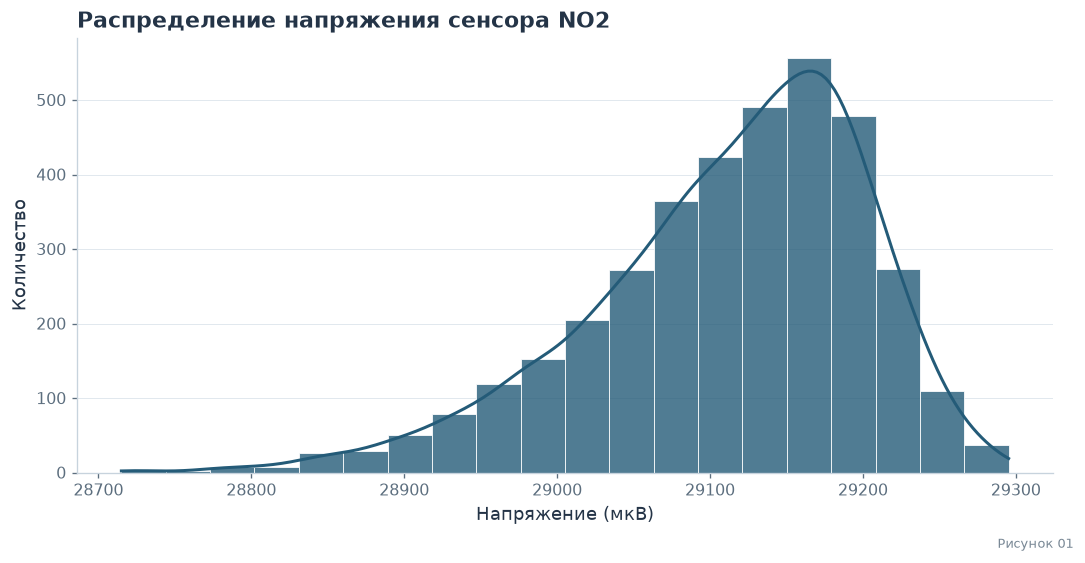

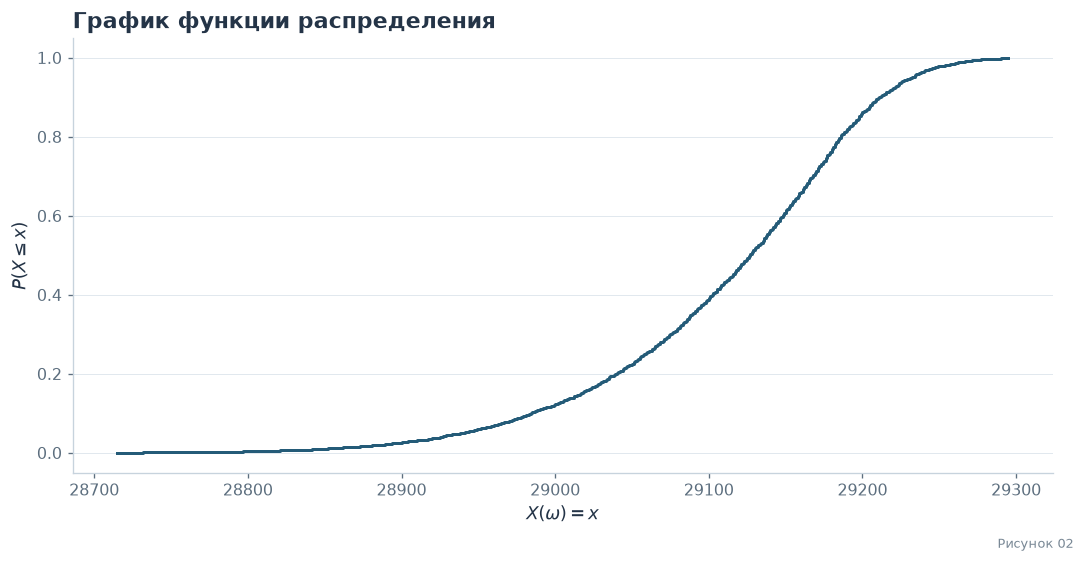


Сумма: 107306226.23449999
Среднее: 29111.835657759086
Медиана: 29128.038145
Минимум: 28715.0
Максимум: 29295.28125
Стандартное отклонение: 90.41962706444696
95-й перцентиль: 29233.165215
Дисперсия: 8175.708958473668
Мода: 29126.09375


In [4]:
no2_all = sensors['ASE_NO2']
no2 = sensors['ASE_NO2'].dropna()

print(f"\nРазмер данных до очистки: {no2_all.shape[0]} наблюдений.")
print(f"Размер данных после очистки: {no2.shape[0]} наблюдений.\n")

no2.head(5)

#распределения
fig, axes = plt.subplots(figsize=(8, 4))

sns.histplot(
    data=no2,
    kde=True,
    ax=axes,
    bins = 20
)
axes.set_title("Распределение напряжения сенсора NO2")
axes.set_xlabel("Напряжение (мкВ)")
axes.set_ylabel("Количество")

plt.tight_layout()
plt.show()


#график ф-ции распределения
no2_round = no2.apply(lambda x: int(round(x)))
voltage = no2_round.value_counts().reset_index()
voltage['p_i'] = voltage['count'].apply(lambda x: x/no2.shape[0])

p_accum = 0

def P_func(x):
    global p_accum
    p_accum += x
    return p_accum

voltage = voltage.sort_values(by='ASE_NO2')
voltage['P'] = voltage ['p_i'].apply(lambda x: P_func(x))

fig, ax = plt.subplots(figsize=(15, 4))
ax.step(voltage['ASE_NO2'],voltage['P'])
ax.set_title("График функции распределения")
ax.set_xlabel(r"$X(\omega) = x$")
ax.set_ylabel(r"$P(X \leq x)$")
ax.grid(True, alpha=0.3)

plt.show()

#остальные метрики
print(f"\nСумма:", no2.sum())
print("Среднее:", no2.mean())
print("Медиана:", no2.median())
print("Минимум:", no2.min())
print("Максимум:", no2.max())
print("Стандартное отклонение:", no2.std())
print("95-й перцентиль:", no2.quantile(0.95))
print("Дисперсия:", no2.var())
print("Мода:", no2.mode().iloc[0])


<a id="no2-model" name="no2-model" class="lab-anchor"></a>

#### 2.2.1 · Математическая база распределения

Сенсор измеряет напряжение электрода, на что влияет множество мелких случайных факторов (ветер, машины, погрешность прибора). Если случайная величина формируется под воздействием множества независимых факторов, ее распределение стремится к нормальному.
Но физически - повышение концентрации NO2 понижает показатель датчика. Эти скачки концентрации (например, из-за частых автомобильных пробок в месте измерения) привело к ассиметрии графика распределения и образованию вытянутого левого хвоста.

Математически плотность вероятности ассиметричного нормального распределение задается:
$$f(x) = \frac{2}{\omega} \phi\left(\frac{x - \xi}{\omega}\right) \Phi\left(\alpha \left(\frac{x - \xi}{\omega}\right)\right)$$

Где:
* $\phi(t)$ — стандартная нормальная плотность распределения.
* $\Phi(t)$ — функция распределения стандартного нормального закона.
* $\xi$ — параметр сдвига.
* $\omega$ — параметр масштаба.
* $\alpha$ — параметр асимметрии.

Нулевая гипотеза: распределение напряжения сенсора NO2 соответствует нормальному
Альтернативная: распределение отличается от нормального, присутствует ассиметрия

<div class="lab-links">Связанные разделы: <a href="#no2-test">проверка гипотезы</a> · <a href="#no2-normalization">нормализация</a></div>

<a id="no2-test" name="no2-test" class="lab-anchor"></a>

#### 2.2.2 · Проверка гипотезы

In [5]:
import scipy.stats as stats

stat, p_value = stats.normaltest(no2)

print(f"Статистика критерия: {stat}")
print(f"p-value: {p_value}")

if p_value < 0.05:
    print("Нулевая гипотеза не верна")
else:
    print("Нулевая гипотеза верна")


Статистика критерия: 377.24614043412896
p-value: 1.2079291032735805e-82
Нулевая гипотеза не верна


<a id="no2-normalization" name="no2-normalization" class="lab-anchor"></a>

#### 2.2.3 · Нормализация

<a id="fig03" name="fig03" class="lab-anchor"></a>

<div class="lab-caption">Рисунок 03: нормализация NO2</div>

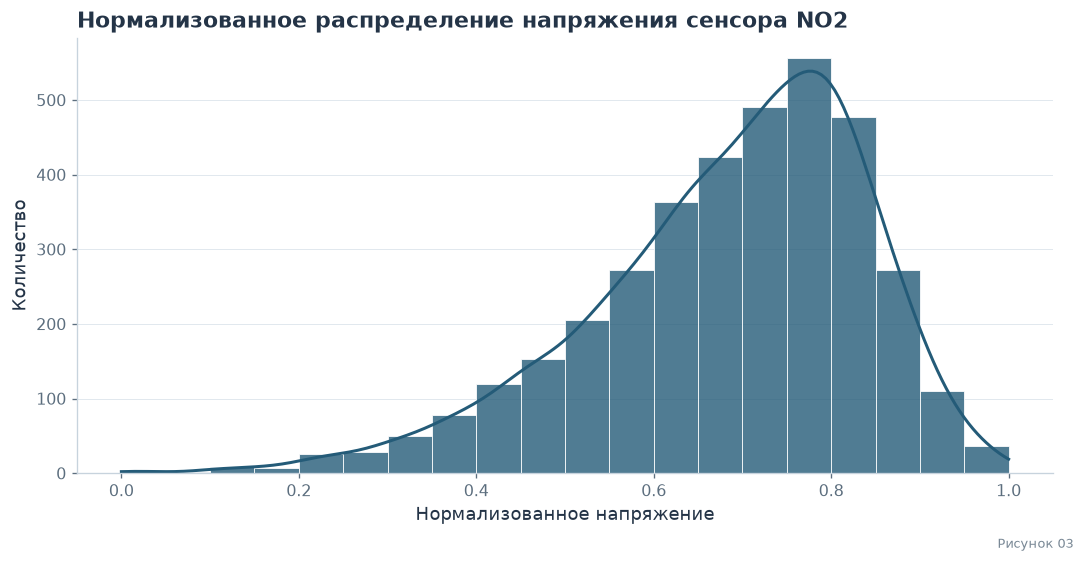

Новый минимум: 0.0
Новый максимум: 1.0
Новое среднее: 0.6838677930039768


In [6]:
min_no2 = no2.min()
max_no2 = no2.max()
no2_normalized = (no2 - min_no2) / (max_no2 - min_no2)

fig, axes = plt.subplots(figsize=(8, 4))
sns.histplot(
    data=no2_normalized,
    kde=True,
    ax=axes,
    bins=20,
)

axes.set_title("Нормализованное распределение напряжения сенсора NO2")
axes.set_xlabel("Нормализованное напряжение")
axes.set_ylabel("Количество")
axes.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Новый минимум:", no2_normalized.min())
print(f"Новый максимум:", no2_normalized.max())
print(f"Новое среднее:", no2_normalized.mean())

<a id="no2-estimates" name="no2-estimates" class="lab-anchor"></a>

### 2.3 · Independence & Estimations

Для проверки состоятельности оценки проверим, как среднее значение ведет себя при увеличении количества случайных показаний сенсора.

<div class="lab-links">Связанные разделы: <a href="#no2-samples">сравнение выборок</a> · <a href="#no2-conclusion">вывод</a></div>

<a id="fig04" name="fig04" class="lab-anchor"></a>

<div class="lab-caption">Рисунок 04: оценка среднего NO2</div>

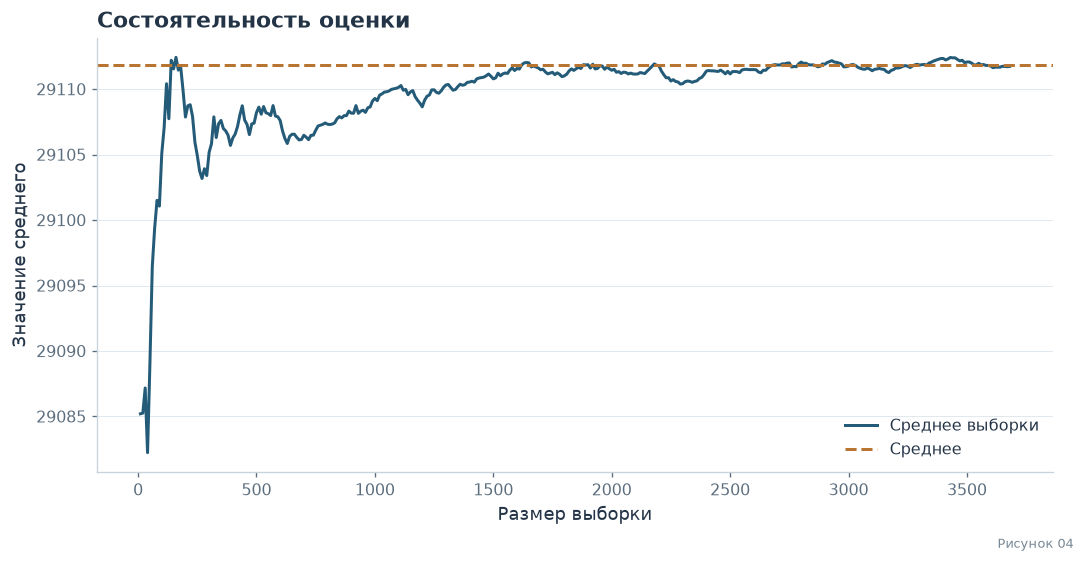

In [7]:
random_no2 = no2.sample(frac=1, random_state=40).values

sizes = np.arange(10, len(random_no2), 10)
means = [random_no2[:n].mean() for n in sizes]

plt.figure(figsize=(10, 4))
plt.plot(sizes, means, label='Среднее выборки', color='blue')
plt.axhline(no2.mean(), color='red', linestyle='--', label='Среднее')

plt.title('Состоятельность оценки')
plt.xlabel('Размер выборки')
plt.ylabel('Значение среднего')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Можно заметить, как значение среднего перестает колебаться и сводится к исходному при увеличении размера выборки.
После отметки в 600 показаний, среднее перестает сильно колебаться. Возьмем выборку размером в 600 значений и проверим ее статистику.

<a id="no2-samples" name="no2-samples" class="lab-anchor"></a>

#### 2.3.1 · Сравнение выборок

<a id="table02" name="table02" class="lab-anchor"></a>

**Таблица 02 · Сравнение выборок NO2**

In [8]:
n_samples = 600

no_return = no2.sample(n=n_samples, replace=False, random_state=40)
with_return = no2.sample(n=n_samples, replace=True, random_state=40)

def get_stat(data, column_name):
    stats = {
        "Сумма": data.sum(),
        "Среднее": data.mean(),
        "Медиана": data.median(),
        "Минимум": data.min(),
        "Максимум": data.max(),
        "Стандартное отклонение": data.std(),
        "95-й перцентиль": data.quantile(0.95),
        "Дисперсия": data.var(),
        "Мода": data.mode().iloc[0],
    }
    return pd.DataFrame(stats.values(), index=stats.keys(), columns=[column_name])

df_gen = get_stat(no2, "Генеральная совокупность")
df_no_r = get_stat(no_return, "Без возвращения ")
df_with_r = get_stat(with_return, "С возвращением")

table = pd.concat([df_gen, df_no_r, df_with_r], axis=1)
display(table)

,Генеральная совокупность,Без возвращения,С возвращением
Сумма,1.073062e+08,1.746457e+07,1.746633e+07
Среднее,2.911184e+04,2.910761e+04,2.911055e+04
Медиана,2.912804e+04,2.912511e+04,2.912652e+04
Минимум,2.871500e+04,2.873198e+04,2.879690e+04
Максимум,2.929528e+04,2.929450e+04,2.927598e+04
Стандартное отклонение,9.041963e+01,9.166015e+01,8.787437e+01
95-й перцентиль,2.923317e+04,2.922880e+04,2.922898e+04
Дисперсия,8.175709e+03,8.401583e+03,7.721905e+03
Мода,2.912609e+04,2.906138e+04,2.921608e+04


<a id="no2-conclusion" name="no2-conclusion" class="lab-anchor"></a>

**Вывод по сравнению выборок**

Все данные, кроме суммы, очень близки к генеральной совокупности, что показывает выборку объемом 600 подходящей для суждения о ней.
Дисперсия выборки с возвращением заметно ниже, так как в нее могли попасть продублированные строки, в остальном данные не отличаются.
Выборка без возвращения в целом более похожа на оригинальную

<nav class="lab-nav" aria-label="Навигация по отчёту"><a href="#data">← Исходные данные</a><a href="#contents">↑ Оглавление</a><a href="#rv-temp">Температура →</a></nav>

<a id="rv-temp" name="rv-temp" class="lab-anchor"></a>

## 3 · Random Variable 02: Сигнал сенсора температуры (ASE_T)

<a id="temp-description" name="temp-description" class="lab-anchor"></a>

### 3.1 · Description

Случайная величина 2 — значение напряжения на сенсоре температуры, измеряемое на автомобильном перекрестке. Показание сенсора нельзя просто рассчитать по формуле, так как температура воздуха зависит от многих факторов: погоды, времени суток, количества машин и ветра. Также присутствует погрешность самого сенсора и броуновское движение молекул воздуха

<div class="lab-links">Связанные разделы: <a href="#rv-no2">сигнал NO2</a> · <a href="#dependence">исследование связи</a></div>

<a id="temp-eda" name="temp-eda" class="lab-anchor"></a>

### 3.2 · EDA & Distribution

<a id="fig05" name="fig05" class="lab-anchor"></a>

<div class="lab-caption">Рисунки 05–06: распределение и функция распределения температуры</div>


Размер данных до очистки: 3739 наблюдений.
Размер данных после очистки: 3736 наблюдений.



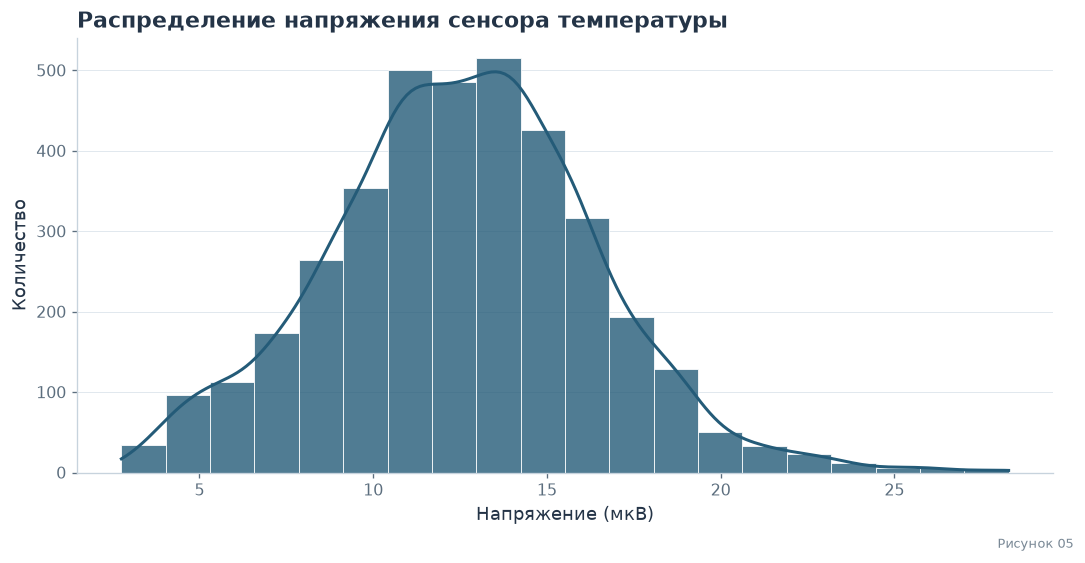

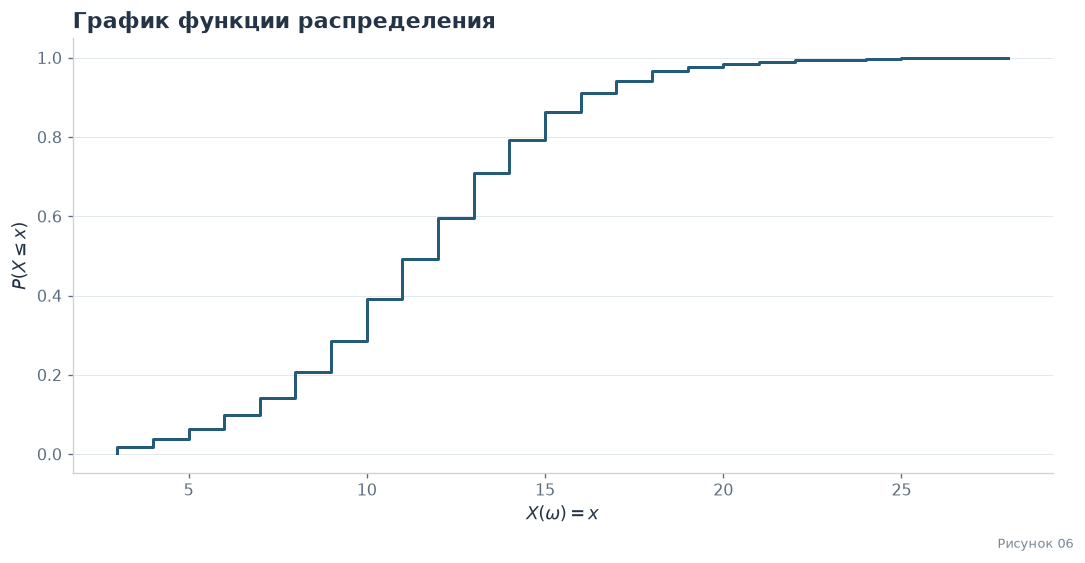


Сумма: 46886.3627801
Среднее: 12.549882971118842
Медиана: 12.594052795
Минимум: 2.752066326
Максимум: 28.28757534
Стандартное отклонение: 3.842404111246628
95-й перцентиль: 18.747636445
Дисперсия: 14.76406935412499
Мода: 8.736985326


In [9]:
temp_all = sensors['ASE_T']
temp = sensors['ASE_T'].dropna()

print(f"\nРазмер данных до очистки: {temp_all.shape[0]} наблюдений.")
print(f"Размер данных после очистки: {temp.shape[0]} наблюдений.\n")

temp.head(5)

# распределения
fig, axes = plt.subplots(figsize=(8, 4))

sns.histplot(
    data=temp,
    kde=True,
    ax=axes,
    bins=20
)
axes.set_title("Распределение напряжения сенсора температуры")
axes.set_xlabel("Напряжение (мкВ)")
axes.set_ylabel("Количество")

plt.tight_layout()
plt.show()


# график ф-ции распределения
temp_round = temp.apply(lambda x: int(round(x)))
voltage = temp_round.value_counts().reset_index()
voltage['p_i'] = voltage['count'].apply(lambda x: x/temp.shape[0])

p_accum = 0

def P_func(x):
    global p_accum
    p_accum += x
    return p_accum

voltage = voltage.sort_values(by='ASE_T')
voltage['P'] = voltage['p_i'].apply(lambda x: P_func(x))

fig, ax = plt.subplots(figsize=(15, 4))
ax.step(voltage['ASE_T'], voltage['P'])
ax.set_title("График функции распределения")
ax.set_xlabel(r"$X(\omega) = x$")
ax.set_ylabel(r"$P(X \leq x)$")
ax.grid(True, alpha=0.3)

plt.show()

# остальные метрики
print(f"\nСумма:", temp.sum())
print("Среднее:", temp.mean())
print("Медиана:", temp.median())
print("Минимум:", temp.min())
print("Максимум:", temp.max())
print("Стандартное отклонение:", temp.std())
print("95-й перцентиль:", temp.quantile(0.95))
print("Дисперсия:", temp.var())
print("Мода:", temp.mode().iloc[0])

<a id="temp-model" name="temp-model" class="lab-anchor"></a>

#### 3.2.1 · Математическая база распределения

Сенсор измеряет напряжение, на что влияет множество мелких случайных факторов (погода, ветер, машины, погрешность прибора). Если случайная величина формируется под воздействием множества независимых факторов, ее распределение стремится к нормальному

Физически - температура воздуха на перекрестке меняется в течение дня, а также под влиянием автомобильных выбросов тепла. Эти колебания (например, из-за частых машин) приводят к асимметрии графика распределения и образованию вытянутого хвоста

Математически плотность вероятности асимметричного нормального распределения задается:
$$f(x) = \frac{2}{\omega} \phi\left(\frac{x - \xi}{\omega}\right) \Phi\left(\alpha \left(\frac{x - \xi}{\omega}\right)\right)$$

Где:
* $\phi(t)$ — стандартная нормальная плотность распределения.
* $\Phi(t)$ — функция распределения стандартного нормального закона.
* $\xi$ — параметр сдвига.
* $\omega$ — параметр масштаба.
* $\alpha$ — параметр асимметрии.

Нулевая гипотеза: распределение напряжения сенсора температуры соответствует нормальному, альтернативная: распределение отличается от нормального, присутствует асимметрия

<div class="lab-links">Связанные разделы: <a href="#temp-test">проверка гипотезы</a> · <a href="#temp-normalization">нормализация</a></div>

<a id="temp-test" name="temp-test" class="lab-anchor"></a>

#### 3.2.2 · Проверка гипотезы

In [10]:
import scipy.stats as stats

stat, p_value = stats.normaltest(temp)

print(f"Статистика критерия: {stat}")
print(f"p-value: {p_value}")

if p_value < 0.05:
    print("Нулевая гипотеза не верна")
else:
    print("Нулевая гипотеза верна")

Статистика критерия: 33.48183282258036
p-value: 5.364291633817727e-08
Нулевая гипотеза не верна


<a id="temp-normalization" name="temp-normalization" class="lab-anchor"></a>

#### 3.2.3 · Нормализация

<a id="fig07" name="fig07" class="lab-anchor"></a>

<div class="lab-caption">Рисунок 07: нормализация температуры</div>

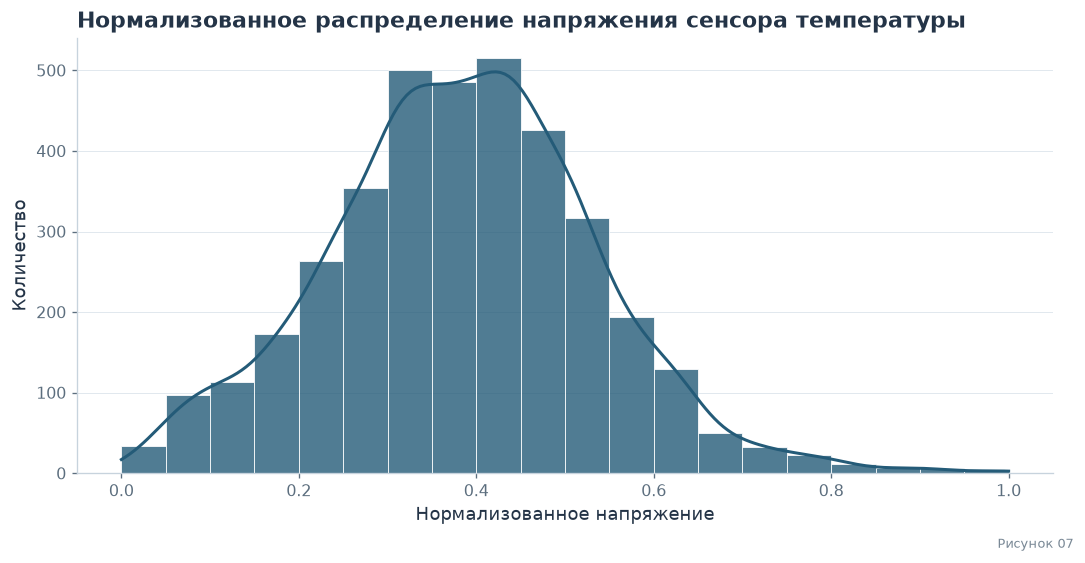

Новый минимум: 0.0
Новый максимум: 1.0
Новое среднее: 0.38369380613275145


In [11]:
min_temp = temp.min()
max_temp = temp.max()
temp_normalized = (temp - min_temp) / (max_temp - min_temp)

fig, axes = plt.subplots(figsize=(8, 4))
sns.histplot(
    data=temp_normalized,
    kde=True,
    ax=axes,
    bins=20,
)
axes.set_title("Нормализованное распределение напряжения сенсора температуры")
axes.set_xlabel("Нормализованное напряжение")
axes.set_ylabel("Количество")
axes.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Новый минимум:", temp_normalized.min())
print(f"Новый максимум:", temp_normalized.max())
print(f"Новое среднее:", temp_normalized.mean())

<a id="temp-estimates" name="temp-estimates" class="lab-anchor"></a>

### 3.3 · Independence & Estimations

Для проверки состоятельности оценки проверим, как среднее значение ведет себя при увеличении количества случайных показаний сенсора

<div class="lab-links">Связанные разделы: <a href="#temp-samples">сравнение выборок</a> · <a href="#temp-conclusion">вывод</a></div>

<a id="fig08" name="fig08" class="lab-anchor"></a>

<div class="lab-caption">Рисунок 08: оценка среднего температуры</div>

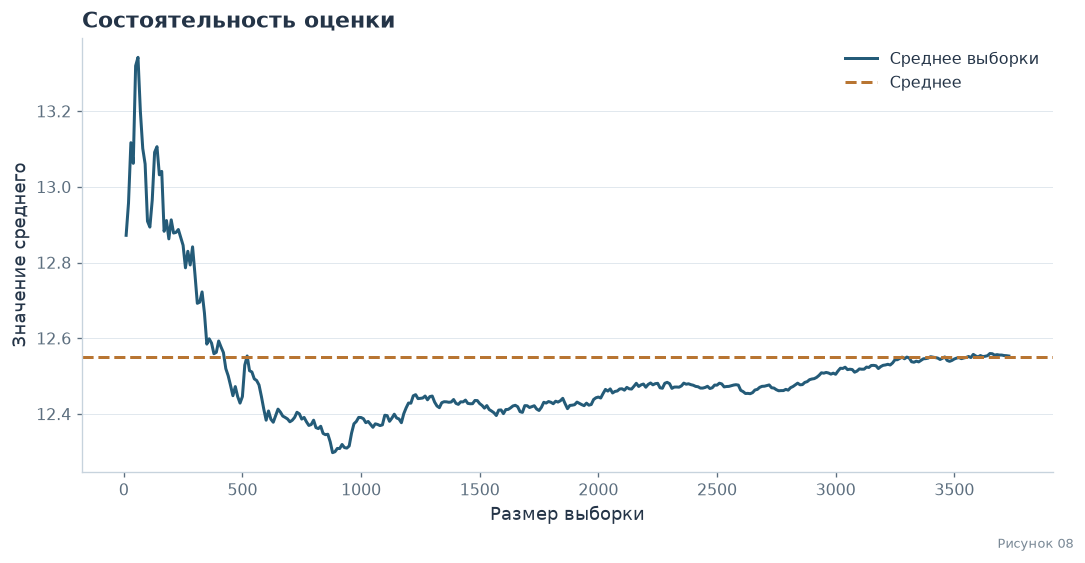

In [12]:
random_temp = temp.sample(frac=1, random_state=40).values

sizes = np.arange(10, len(random_temp), 10)
means = [random_temp[:n].mean() for n in sizes]

plt.figure(figsize=(10, 4))
plt.plot(sizes, means, label='Среднее выборки', color='blue')
plt.axhline(temp.mean(), color='red', linestyle='--', label='Среднее')

plt.title('Состоятельность оценки')
plt.xlabel('Размер выборки')
plt.ylabel('Значение среднего')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Можно заметить, как значение среднего перестает колебаться и сводится к исходному при увеличении размера выборки.
После отметки в 600 показаний, среднее перестает сильно колебаться. Возьмем выборку размером в 600 значений и проверим ее статистику

<a id="temp-samples" name="temp-samples" class="lab-anchor"></a>

#### 3.3.1 · Сравнение выборок

<a id="table03" name="table03" class="lab-anchor"></a>

**Таблица 03 · Сравнение выборок температуры**

In [13]:
n_samples = 600

no_return = temp.sample(n=n_samples, replace=False, random_state=40)
with_return = temp.sample(n=n_samples, replace=True, random_state=40)

def get_stat(data, column_name):
    stats = {
        "Сумма": data.sum(),
        "Среднее": data.mean(),
        "Медиана": data.median(),
        "Минимум": data.min(),
        "Максимум": data.max(),
        "Стандартное отклонение": data.std(),
        "95-й перцентиль": data.quantile(0.95),
        "Дисперсия": data.var(),
        "Мода": data.mode().iloc[0],
    }
    return pd.DataFrame(stats.values(), index=stats.keys(), columns=[column_name])

df_gen = get_stat(temp, "Генеральная совокупность")
df_no_r = get_stat(no_return, "Без возвращения ")
df_with_r = get_stat(with_return, "С возвращением")

table = pd.concat([df_gen, df_no_r, df_with_r], axis=1)
display(table)

,Генеральная совокупность,Без возвращения,С возвращением
Сумма,46886.362780,7430.257399,7604.712319
Среднее,12.549883,12.383762,12.674521
Медиана,12.594053,12.568173,12.834649
Минимум,2.752066,3.220754,2.752066
Максимум,28.287575,26.637090,25.848898
Стандартное отклонение,3.842404,3.698433,3.764880
95-й перцентиль,18.747636,18.123621,18.818729
Дисперсия,14.764069,13.678408,14.174325
Мода,8.736985,3.220754,13.043959


<a id="temp-conclusion" name="temp-conclusion" class="lab-anchor"></a>

**Вывод по сравнению выборок**

Все данные, кроме суммы, очень близки к генеральной совокупности, что показывает выборку объемом 600 подходящей.
Дисперсия выборки с возвращением заметно ниже, так как в нее могли попасть продублированные строки, в остальном данные не отличаются.
Выборка без возвращения в целом более похожа на оригинальную. Также заметим что, в отличие от NO2, распределение температуры имеет несколько пиков, что физически объясняется изменением температуры в течение суток, а тест на нормальность подтверждает, что распределение не является нормальным

<nav class="lab-nav" aria-label="Навигация по отчёту"><a href="#rv-no2">← NO2</a><a href="#contents">↑ Оглавление</a><a href="#dependence">Зависимость →</a></nav>

<a id="dependence" name="dependence" class="lab-anchor"></a>

## 4 · Зависимость NO2 от температуры

Исследуем, влияет ли температура воздуха на показания сенсора NO2

<div class="lab-links">Связанные разделы: <a href="#no2-description">описание NO2</a> · <a href="#temp-description">описание температуры</a> · <a href="#dependence-conclusion">вывод</a></div>

<a id="dependence-test" name="dependence-test" class="lab-anchor"></a>

### 4.1 · Коэффициент корреляции

In [14]:
from scipy.stats import pearsonr

df_corr = sensors[['ASE_T', 'ASE_NO2']].dropna()

correlation, p_value = pearsonr(df_corr['ASE_T'], df_corr['ASE_NO2'])

print(f"Коэффициент корреляции Пирсона (r): {correlation:.4f}")
print(f"p-value: {p_value:.4e}")

if p_value < 0.05:
    print("Вывод: Связь статистически значима (p-value < 0.05).")
    if correlation > 0:
        print("Направление связи: Прямая (при росте температуры NO2 растет).")
    else:
        print("Направление связи: Обратная (при росте температуры NO2 падает).")
else:
    print("Вывод: Статистически значимой связи не обнаружено (p-value >= 0.05).")

Коэффициент корреляции Пирсона (r): -0.2372
p-value: 2.6736e-48
Вывод: Связь статистически значима (p-value < 0.05).
Направление связи: Обратная (при росте температуры NO2 падает).


<a id="dependence-plots" name="dependence-plots" class="lab-anchor"></a>

### 4.2 · Визуализация зависимости

<a id="fig09" name="fig09" class="lab-anchor"></a>

<div class="lab-caption">Рисунок 09: зависимость NO2 от температуры</div>

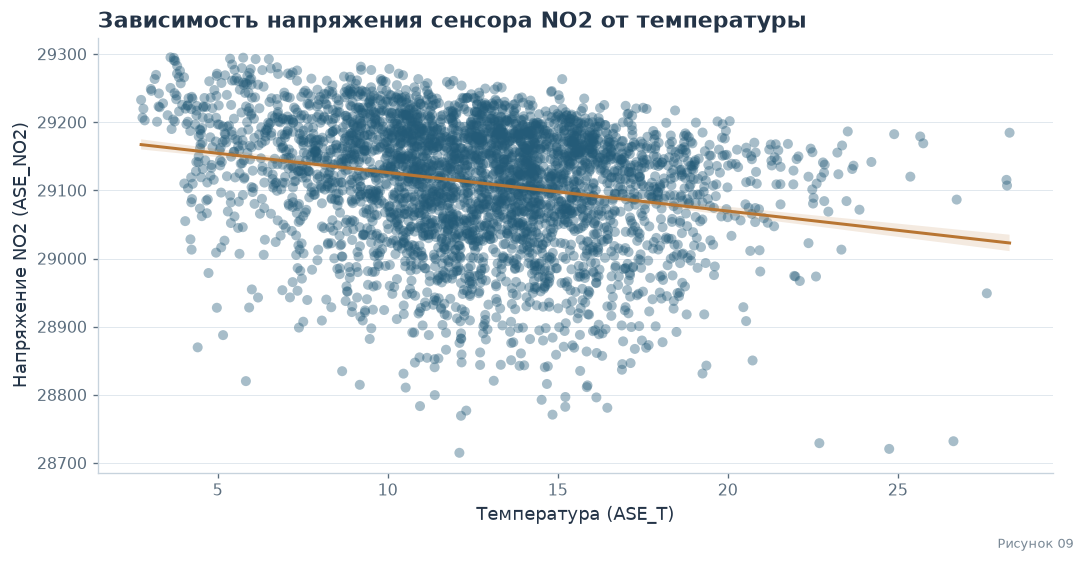

In [15]:
plt.figure(figsize=(10, 6))

sns.scatterplot(data=df_corr, x='ASE_T', y='ASE_NO2', alpha=0.4, color='orange')

sns.regplot(data=df_corr, x='ASE_T', y='ASE_NO2', scatter=False, color='red', line_kws={'linewidth': 2})

plt.title('Зависимость напряжения сенсора NO2 от температуры')
plt.xlabel('Температура (ASE_T)')
plt.ylabel('Напряжение NO2 (ASE_NO2)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

<a id="fig10" name="fig10" class="lab-anchor"></a>

<div class="lab-caption">Рисунок 10: матрица корреляции</div>

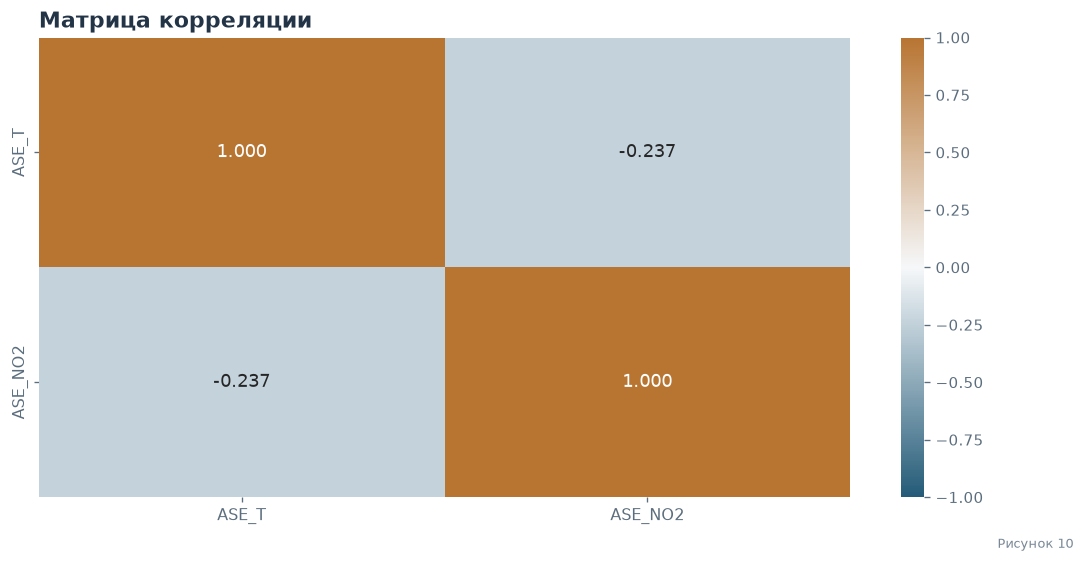

In [16]:
plt.figure(figsize=(6, 4))
corr_matrix = df_corr.corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".3f")
plt.title('Матрица корреляции')
plt.tight_layout()
plt.show()

<a id="dependence-conclusion" name="dependence-conclusion" class="lab-anchor"></a>

### 4.3 · Вывод по зависимости NO2 от температуры


Получилось, связь между температурой и показаниями сенсора NO2 все таки есть, об этом говорит и наклон красной линии тренда на графике, и коэффициент корреляции -0.237 , так как p-value < 0.05, то связь не случайная

Поскольку связь все равно слабая, сама температура воздуха не главная причина изменения концентрации NO2. Например, в холода машины дольше греются, а выхлопные газы рассеиваются хуже, из-за чего уровень газа в воздухе в среднем выше, чем в теплую погоду. Также возможна ошибка прибора, что сам датчик может менять показания в зависимости от температуры

<nav class="lab-nav" aria-label="Навигация по отчёту"><a href="#rv-temp">← Температура</a><a href="#contents">↑ Оглавление</a><a href="#rv-co">CO →</a></nav>

<a id="rv-co" name="rv-co" class="lab-anchor"></a>

## 5 · Random Variable 03: Сигнал сенсора CO

<a id="co-description" name="co-description" class="lab-anchor"></a>

### 5.1 · Description

Случайная величина 3 - сигнал электрохимического сенсора CO (`ASE_CO`), который снимается каждый час на автомобильном перекрестке. Вычислить его по формуле нельзя: значение зависит, в частности, от того, сколько машин проехало и как дует ветер, и к этому добавляется собственный шум прибора.

<div class="lab-links">Связанные разделы: <a href="#rv-no2">сигнал NO2</a> · <a href="#rv-temp">температура</a></div>

<a id="co-eda" name="co-eda" class="lab-anchor"></a>

### 5.2 · EDA & Distribution

<a id="fig11" name="fig11" class="lab-anchor"></a>

<div class="lab-caption">Рисунки 11–12: распределение и функция распределения CO</div>


Размер данных до очистки: 3739 наблюдений.
Размер данных после очистки: 3686 наблюдений.



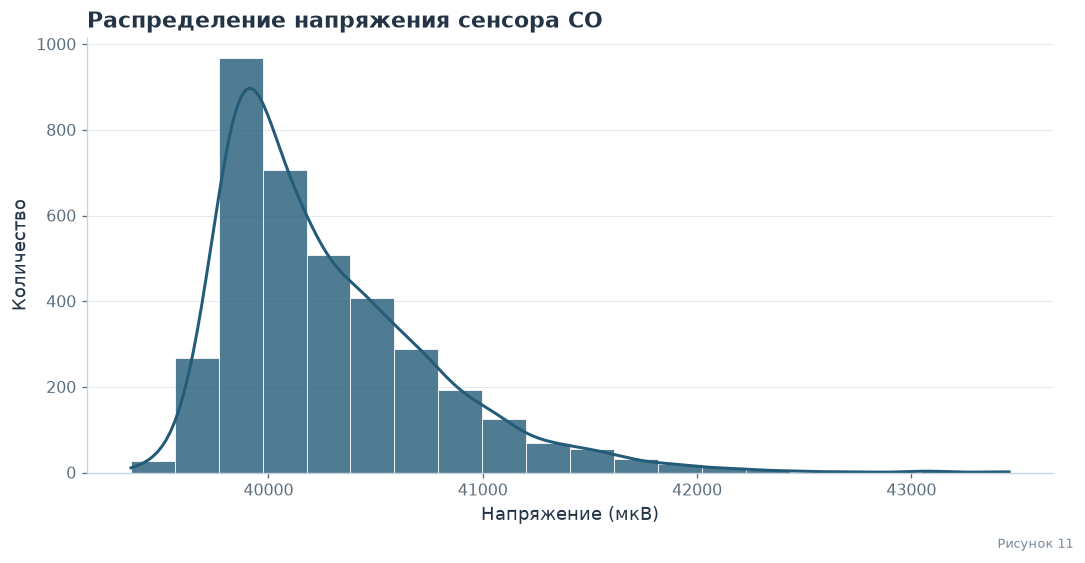

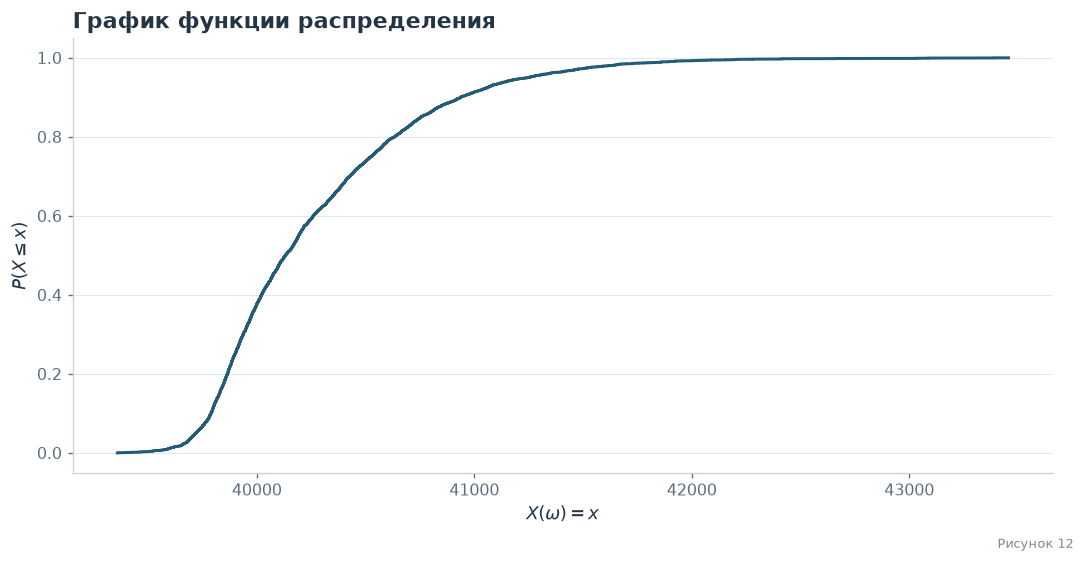


Сумма: 148429693.67587
Среднее: 40268.50072595497
Медиана: 40132.16728
Минимум: 39358.04688
Максимум: 43455.98346
Стандартное отклонение: 499.6717627929245
95-й перцентиль: 41247.7557475
Дисперсия: 249671.87053258857
Мода: 39752.20313


In [17]:
co_all = sensors['ASE_CO']
co = sensors['ASE_CO'].dropna()

print(f"\nРазмер данных до очистки: {co_all.shape[0]} наблюдений.")
print(f"Размер данных после очистки: {co.shape[0]} наблюдений.\n")

co.head(5)

#распределения
fig, axes = plt.subplots(figsize=(8, 4))

sns.histplot(
    data=co,
    kde=True,
    ax=axes,
    bins = 20
)
axes.set_title("Распределение напряжения сенсора CO")
axes.set_xlabel("Напряжение (мкВ)")
axes.set_ylabel("Количество")

plt.tight_layout()
plt.show()


#график ф-ции распределения
co_round = co.apply(lambda x: int(round(x)))
voltage = co_round.value_counts().reset_index()
voltage['p_i'] = voltage['count'].apply(lambda x: x/co.shape[0])

p_accum = 0

def P_func(x):
    global p_accum
    p_accum += x
    return p_accum

voltage = voltage.sort_values(by='ASE_CO')
voltage['P'] = voltage ['p_i'].apply(lambda x: P_func(x))

fig, ax = plt.subplots(figsize=(15, 4))
ax.step(voltage['ASE_CO'],voltage['P'])
ax.set_title("График функции распределения")
ax.set_xlabel(r"$X(\omega) = x$")
ax.set_ylabel(r"$P(X \leq x)$")
ax.grid(True, alpha=0.3)

plt.show()

#остальные метрики
print(f"\nСумма:", co.sum())
print("Среднее:", co.mean())
print("Медиана:", co.median())
print("Минимум:", co.min())
print("Максимум:", co.max())
print("Стандартное отклонение:", co.std())
print("95-й перцентиль:", co.quantile(0.95))
print("Дисперсия:", co.var())
print("Мода:", co.mode().iloc[0])

<a id="co-model" name="co-model" class="lab-anchor"></a>

#### 5.2.1 · Математическая база распределения


Проверим гипотезу о нормальности.
$H_0$: распределение сигнала CO нормальное.
$H_1$: распределение отличается от нормального.

<div class="lab-links">Связанные разделы: <a href="#co-test">проверка гипотезы</a> · <a href="#co-fit">сравнение моделей</a></div>

<a id="co-test" name="co-test" class="lab-anchor"></a>

#### 5.2.2 · Проверка гипотезы

In [18]:
import scipy.stats as stats

stat, p_value = stats.normaltest(co)

print(f"Статистика критерия: {stat}")
print(f"p-value: {p_value}")

if p_value < 0.05:
    print("Нулевая гипотеза отвергается: распределение не нормальное")
else:
    print("Нет оснований отвергнуть нулевую гипотезу")

Статистика критерия: 1028.7669622714538
p-value: 4.037314305072088e-224
Нулевая гипотеза отвергается: распределение не нормальное


<a id="co-fit" name="co-fit" class="lab-anchor"></a>

#### 5.2.3 · Сравнение теоретических распределений

<a id="fig13" name="fig13" class="lab-anchor"></a>

<div class="lab-caption">Рисунок 13: сравнение моделей CO</div>

Skew-normal: alpha = 7.688, xi = 39687.0, omega = 766.6
Асимметрия модели skew-normal: 0.93
Асимметрия данных: 1.467
AIC skew-normal: 54990.6
AIC lognormal:   54961.4


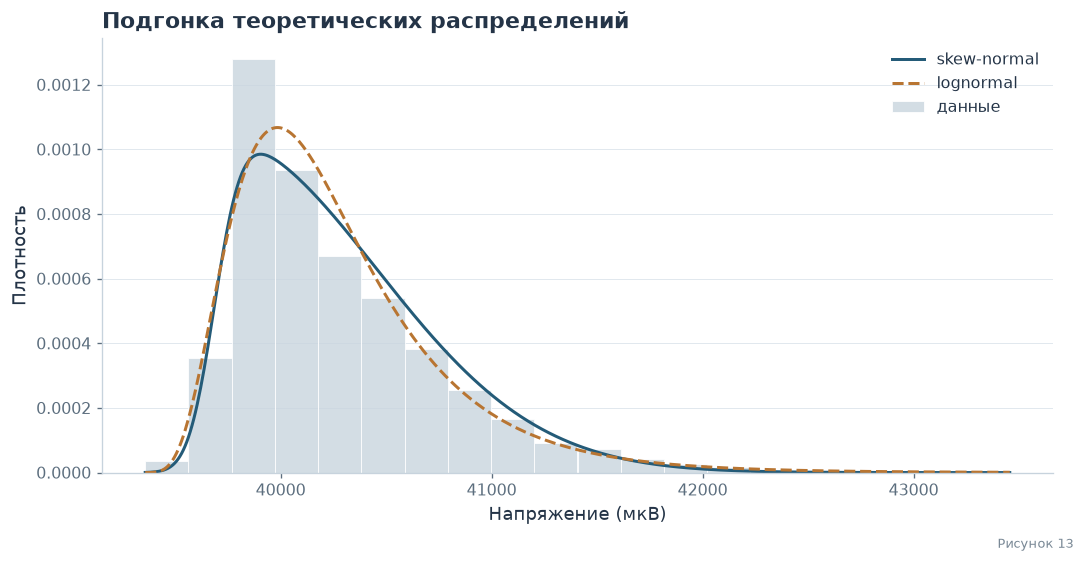

In [19]:
# подгонка теоретических распределений к данным (метод максимального правдоподобия)
a, loc_sn, scale_sn = stats.skewnorm.fit(co)
s, loc_ln, scale_ln = stats.lognorm.fit(co)

print("Skew-normal: alpha = {:.3f}, xi = {:.1f}, omega = {:.1f}".format(a, loc_sn, scale_sn))
print("Асимметрия модели skew-normal:", round(float(stats.skewnorm.stats(a, loc_sn, scale_sn, moments='s')), 3))
print("Асимметрия данных:", round(co.skew(), 3))

# сравнение моделей по AIC (чем меньше, тем лучше)
def aic(dist, params):
    return 2 * len(params) - 2 * dist.logpdf(co, *params).sum()

aic_sn = aic(stats.skewnorm, (a, loc_sn, scale_sn))
aic_ln = aic(stats.lognorm, (s, loc_ln, scale_ln))
print("AIC skew-normal:", round(aic_sn, 1))
print("AIC lognormal:  ", round(aic_ln, 1))

# теоретические плотности поверх гистограммы
x = np.linspace(co.min(), co.max(), 500)
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(co, stat='density', bins=20, ax=ax, color='lightgray', label='данные')
ax.plot(x, stats.skewnorm.pdf(x, a, loc_sn, scale_sn), label='skew-normal')
ax.plot(x, stats.lognorm.pdf(x, s, loc_ln, scale_ln), label='lognormal')
ax.set_title("Подгонка теоретических распределений")
ax.set_xlabel("Напряжение (мкВ)")
ax.set_ylabel("Плотность")
ax.legend()
plt.tight_layout()
plt.show()

<a id="co-test-repeat" name="co-test-repeat" class="lab-anchor"></a>

#### 5.2.4 · Повторная проверка гипотезы

In [20]:
import scipy.stats as stats

stat, p_value = stats.normaltest(co)

print(f"Статистика критерия: {stat}")
print(f"p-value: {p_value}")

if p_value < 0.05:
    print("Нулевая гипотеза отвергается: распределение не нормальное")
else:
    print("Нет оснований отвергнуть нулевую гипотезу")

Статистика критерия: 1028.7669622714538
p-value: 4.037314305072088e-224
Нулевая гипотеза отвергается: распределение не нормальное


<a id="co-normalization" name="co-normalization" class="lab-anchor"></a>

#### 5.2.5 · Нормализация

<a id="fig14" name="fig14" class="lab-anchor"></a>

<div class="lab-caption">Рисунок 14: нормализация CO</div>

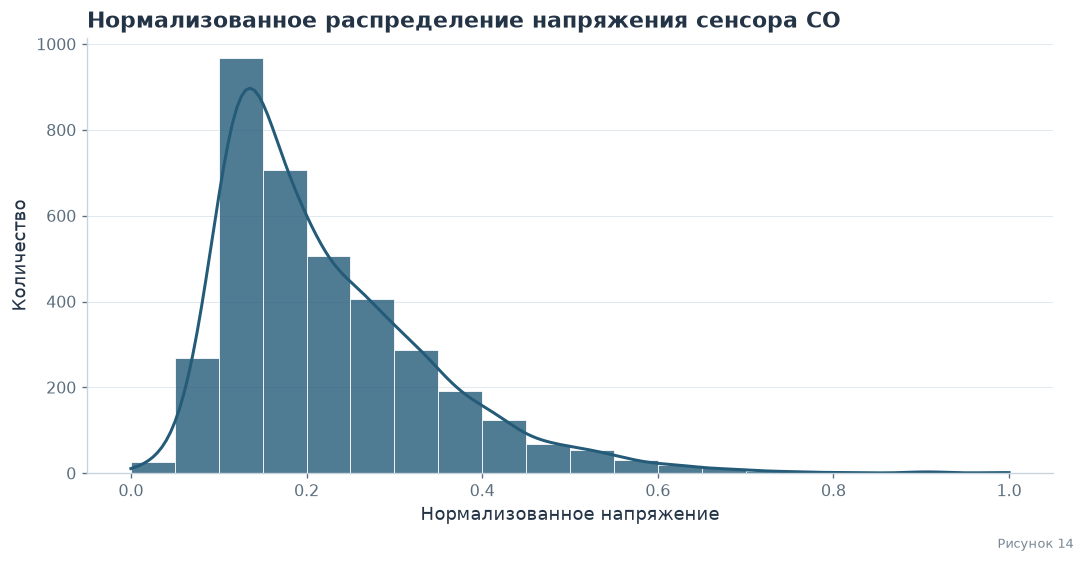

Новый минимум: 0.0
Новый максимум: 1.0
Новое среднее: 0.22217372772395697


In [21]:
min_co = co.min()
max_co = co.max()
co_normalized = (co - min_co) / (max_co - min_co)

fig, axes = plt.subplots(figsize=(8, 4))
sns.histplot(
    data=co_normalized,
    kde=True,
    ax=axes,
    bins=20,
)

axes.set_title("Нормализованное распределение напряжения сенсора CO")
axes.set_xlabel("Нормализованное напряжение")
axes.set_ylabel("Количество")
axes.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Новый минимум:", co_normalized.min())
print(f"Новый максимум:", co_normalized.max())
print(f"Новое среднее:", co_normalized.mean())

<a id="co-estimates" name="co-estimates" class="lab-anchor"></a>

### 5.3 · Independence & Estimations

Проверим состоятельность оценки: посмотрим, как выборочное среднее приближается к среднему всей совокупности при росте числа случайно выбранных показаний.

<div class="lab-links">Связанные разделы: <a href="#co-samples">сравнение выборок</a> · <a href="#co-conclusion">вывод</a></div>

<a id="fig15" name="fig15" class="lab-anchor"></a>

<div class="lab-caption">Рисунок 15: оценка среднего CO</div>

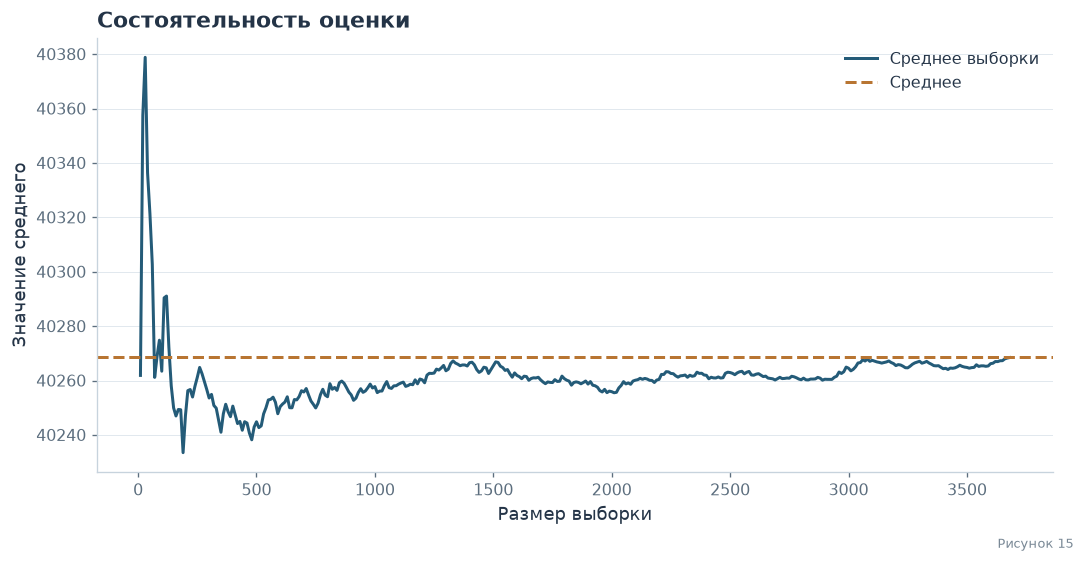

In [22]:
random_co = co.sample(frac=1, random_state=40).values

sizes = np.arange(10, len(random_co), 10)
means = [random_co[:n].mean() for n in sizes]

plt.figure(figsize=(10, 4))
plt.plot(sizes, means, label='Среднее выборки', color='blue')
plt.axhline(co.mean(), color='red', linestyle='--', label='Среднее')

plt.title('Состоятельность оценки')
plt.xlabel('Размер выборки')
plt.ylabel('Значение среднего')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

На графике видно, что колебания среднего с ростом размера выборки затухают, и оно стабилизируется около среднего по всем данным. Начиная примерно с 600 показаний отклонение не превышает около 20 отсч. (меньше 0.05% от среднего). Поэтому для следующего шага возьмем выборку из 600 значений и сравним ее характеристики с генеральными.

<a id="co-samples" name="co-samples" class="lab-anchor"></a>

#### 5.3.1 · Сравнение выборок

<a id="table04" name="table04" class="lab-anchor"></a>

**Таблица 04 · Сравнение выборок CO**

In [23]:
n_samples = 600

no_return = co.sample(n=n_samples, replace=False, random_state=40)
with_return = co.sample(n=n_samples, replace=True, random_state=40)

def get_stat(data, column_name):
    stats = {
        "Сумма": data.sum(),
        "Среднее": data.mean(),
        "Медиана": data.median(),
        "Минимум": data.min(),
        "Максимум": data.max(),
        "Стандартное отклонение": data.std(),
        "95-й перцентиль": data.quantile(0.95),
        "Дисперсия": data.var(),
        "Мода": data.mode().iloc[0],
    }
    return pd.DataFrame(stats.values(), index=stats.keys(), columns=[column_name])

df_gen = get_stat(co, "Генеральная совокупность")
df_no_r = get_stat(no_return, "Без возвращения ")
df_with_r = get_stat(with_return, "С возвращением")

table = pd.concat([df_gen, df_no_r, df_with_r], axis=1)
display(table)

,Генеральная совокупность,Без возвращения,С возвращением
Сумма,1.484297e+08,2.415022e+07,2.417048e+07
Среднее,4.026850e+04,4.025037e+04,4.028413e+04
Медиана,4.013217e+04,4.011883e+04,4.013017e+04
Минимум,3.935805e+04,3.942611e+04,3.941686e+04
Максимум,4.345598e+04,4.221511e+04,4.345598e+04
Стандартное отклонение,4.996718e+02,4.925889e+02,4.942201e+02
95-й перцентиль,4.124776e+04,4.123412e+04,4.125553e+04
Дисперсия,2.496719e+05,2.426438e+05,2.442535e+05
Мода,3.975220e+04,3.942611e+04,3.992811e+04


<a id="co-conclusion" name="co-conclusion" class="lab-anchor"></a>

**Вывод по сравнению выборок**

Основные показатели выборки из 600 значений очень близки к показателям генеральной совокупности: среднее отличается меньше чем на 0.1%. Значит, выборки такого объема подходят для суждения о всех данных.
Дисперсия выборки немного ниже генеральной (примерно на 2-3%), это обычный разброс при таком размере выборки. Максимум и мода отличаются, так как редкие значения могли не попасть в выборку.

<nav class="lab-nav" aria-label="Навигация по отчёту"><a href="#dependence">← Зависимость</a><a href="#contents">↑ Оглавление</a><a href="#resume">Итоги →</a></nav>

<a id="resume" name="resume" class="lab-anchor"></a>

## 6 · Lab resume

В процессе 1 спринта лабораторной работы были исследованы 3 случайной величины: показания датчика NO2, температуры и CO.
Выполнен первичный анализ, подсчитан размер достоверных данных из датасета, подсчитана сумма, среднее, медиана и прочие метрики.
Построен график распределения каждой величины. В случае сенсоров NO2 и CO, наблюдается распределение с ассиметрией. NO2 является окислителем, а CO - восстановителем, повышение их концентраций по разному влияет на датчик, поэтому в графике распределения мы видим хвосты в противоположных сторонах.
В распределении температуры ассиметрия выражена меньше. Ни один из графиков не показывает нормальное распределение, так как помимо множества мелких независящих факторов на датчики влияли автомобильные пробки около места сбора.
Для подтверждения ассиметричности графиков были проверены соответствующие гипотезы.
Для проверки состоятельности оценки построены графики зависимости выборочного среднего от размера выборки, и показана его близость к истинному среднему.
После выбора подходящего, на наш взгляд, размера выборки, для нее были посчитаны все изначальные статистики, что позволило точно убедиться в возможности суждения о генеральной совокупности по выборочной. В каждом случае все данные, кроме суммы, почти совпадали с генеральной совокупностью. Подход без возвращения был более похож на оригинальную выборку.
Для температуры была исследована зависимость ее значения от показателей датчика NO2, для чего была построена матрица корреляции. Результаты показали, что при росте температуры показатель NO2 падает, эта связь не случайна, но слаба. Сама температура не является главной причиной изменения концентрации газа, но на их скачки влияли одни и те же события.

<div class="lab-links">Связанные разделы: <a href="#no2-conclusion">результаты NO2</a> · <a href="#temp-conclusion">результаты температуры</a> · <a href="#dependence-conclusion">зависимость</a> · <a href="#co-conclusion">результаты CO</a></div>

<a id="criteria" name="criteria" class="lab-anchor"></a>

### 6.1 · cat_mark_table

| cat_id | notebook_link | coeff | comment |
|--------|-----------------|-------|---------| 
| lab.ic.01.01 | [Random Variable 01: Сигнал сенсора NO2](#rv-no2)  | 0,15 | |
| lab.ic.01.01 | [Random Variable 02: Сигнал сенсора температуры (ASE_T)](#rv-temp)  | 0,15 | |
| lab.ic.01.01 | [Random Variable 03: Сигнал сенсора CO](#rv-co)  | 0,15 | |
| lab.ic.01.02 | [Зависимость NO2 от температуры](#dependence) | 0,06 | | 
| lab.ic.01.03 | Independence & Estimations: [NO2](#no2-estimates), [ASE_T](#temp-estimates), [CO](#co-estimates) | 0,05 | Отдельным заголовком для каждой величины |
| lab.ic.01.04 | EDA & Distribution: [NO2](#no2-eda), [ASE_T](#temp-eda), [CO](#co-eda) | 0,05 | Отдельным заголовком для каждой величины |
| lab.ic.01.05 | Математическая база распределения: [NO2](#no2-model), [ASE_T](#temp-model), [CO](#co-model) | 0,05 | Для каждой величины подпункт с нормализацией |
| lab.ic.01.06 | Random variable [01](#rv-no2),[03](#rv-co) отличаются от [02](#rv-temp) | 0,1 | |
| lab.ic.01.07 | Математическая база распределения: [NO2](#no2-model), [ASE_T](#temp-model), [CO](#co-model) | 0,05 | Отдельным заголовком для каждой величины |
| lab.ic.01.09 | Independence & Estimations: [NO2](#no2-estimates), [ASE_T](#temp-estimates), [CO](#co-estimates) | 0,05 | |
| lab.ic.01.10 | Independence & Estimations: [NO2](#no2-estimates), [ASE_T](#temp-estimates), [CO](#co-estimates) | 0,05 | |
| lab.ic.01.11 | Математическая база распределения: [NO2](#no2-model), [ASE_T](#temp-model), [CO](#co-model) | 0,05 | Подпункт с гипотезой для каждой величины |

<nav class="lab-nav" aria-label="Навигация по отчёту"><a href="#rv-co">← CO</a><a href="#contents">↑ Оглавление</a></nav>

<a id="figure-index" name="figure-index" class="lab-anchor"></a>

## Указатель рисунков и таблиц

[Рисунки 01–02: распределение и функция распределения NO2](#fig01)  
[Рисунок 03: нормализация NO2](#fig03)  
[Рисунок 04: оценка среднего NO2](#fig04)  
[Рисунки 05–06: распределение и функция распределения температуры](#fig05)  
[Рисунок 07: нормализация температуры](#fig07)  
[Рисунок 08: оценка среднего температуры](#fig08)  
[Рисунок 09: зависимость NO2 от температуры](#fig09)  
[Рисунок 10: матрица корреляции](#fig10)  
[Рисунки 11–12: распределение и функция распределения CO](#fig11)  
[Рисунок 13: сравнение моделей CO](#fig13)  
[Рисунок 14: нормализация CO](#fig14)  
[Рисунок 15: оценка среднего CO](#fig15)  

[Таблица 01 · Первые пять строк исходного датасета](#table01)  
[Таблица 02 · Сравнение выборок NO2](#table02)  
[Таблица 03 · Сравнение выборок температуры](#table03)  
[Таблица 04 · Сравнение выборок CO](#table04)  

<nav class="lab-nav" aria-label="Навигация по отчёту"><a href="#resume">← Итоги</a><a href="#contents">↑ Оглавление</a></nav>